In [2]:
"""
Unit 5: Evolving Your IPD Agent with Genetic Algorithms
========================================================

In Unit 4, you hand-coded agent strategies like Tit-for-Tat.
In Unit 5, you'll use evolution to DISCOVER strategies automatically.

By the end, you'll have an evolved agent saved as a JSON file for the tournament!
"""

# ============================================================================
# SETUP: Import everything from previous units
# ============================================================================

import random
import numpy as np
import json
import matplotlib.pyplot as plt
from agents import Agent, INVEST, UNDERCUT
from game_engine import Game, Tournament

# Import all hand-coded agents from Unit 4
from agents import (
    AlwaysInvestAgent, AlwaysUndercutAgent, TitForTatAgent,
    GrimTriggerAgent, PavlovAgent, TitForTwoTatsAgent,
    GenerousTitForTatAgent, AdaptiveAgent, RandomAgent,
    SuspiciousTitForTatAgent, GradualAgent, HardMajorityAgent,
    SoftMajorityAgent, ProberAgent
)

print("✅ Imports complete!")

✅ Imports complete!


In [3]:

# ============================================================================
# PART 1: THE EVOLVABLE AGENT (PROVIDED - Read but don't modify)
# ============================================================================

class EvolvableAgent(Agent):
    """
    An agent whose strategy is controlled by 6 genes (numbers from 0 to 1).
    
    Think of genes as "strategy dials" you can tune:
    
    Gene[0] - Initial Cooperation (0=hostile start, 1=friendly start)
    Gene[1] - Cooperation Response (if opponent cooperates, how likely to cooperate back?)
    Gene[2] - Defection Response (if opponent defects, how likely to defect back?)
    Gene[3] - Forgiveness (after retaliation, chance to forgive)
    Gene[4] - Memory Length (0=last 1 round, 1=last 10 rounds)
    Gene[5] - Retaliation Threshold (what % of defections triggers retaliation)
    """
    
    def __init__(self, genes=None, name="Evolved Agent"):
        if genes is None:
            # Create random genes if none provided
            genes = [random.random() for _ in range(6)]
        
        self.genes = genes
        super().__init__(name, f"Genes: [{', '.join([f'{g:.2f}' for g in genes])}]")
    
    def choose_action(self) -> bool:
        """Decision logic based on genes - SIMPLIFIED FOR LEARNING"""
        
        # First 3 rounds: use initial cooperation gene
        if self.round_num < 3:
            return random.random() < self.genes[0]
        
        # Calculate memory window (gene[4])
        memory_length = max(1, int(self.genes[4] * 10) + 1)
        recent_history = self.history[-memory_length:]
        
        # Calculate opponent's recent COOPERATION rate (not defection!)
        cooperation_rate = sum(recent_history) / len(recent_history)
        
        # If opponent is mostly cooperating, reciprocate
        if cooperation_rate >= 0.5:
            return random.random() < self.genes[1]  # gene[1] = cooperate response
        
        # If opponent is mostly defecting, retaliate or forgive
        else:
            # Retaliate with probability gene[2]
            if random.random() < self.genes[2]:
                return UNDERCUT
            # Or forgive with probability gene[3]
            elif random.random() < self.genes[3]:
                return INVEST
            else:
                return UNDERCUT


In [10]:

# ============================================================================
# PART 2: DEFINE THE OPPONENT ECOSYSTEM
# ============================================================================

# ============================================================================
# EXPANDED OPPONENT POOL
# ============================================================================

# Full pool of all possible opponents
full_opponent_pool = [
    # Cooperative agents
    AlwaysInvestAgent(),
    TitForTatAgent(),
    GrimTriggerAgent(),
    PavlovAgent(),
    TitForTwoTatsAgent(),
    GenerousTitForTatAgent(),
    AdaptiveAgent(),
    
    # Aggressive agents
    AlwaysUndercutAgent(),
    SuspiciousTitForTatAgent(),
    
    # Sophisticated agents
    GradualAgent(),
    ProberAgent(),
    
    # Majority-based agents
    HardMajorityAgent(),
    SoftMajorityAgent(),
    
    # Random agents with different cooperation levels
    RandomAgent(0.9),
    RandomAgent(0.7),
    RandomAgent(0.5),
    RandomAgent(0.3),
    RandomAgent(0.1),
]

print(f"\n📚 Full opponent library: {len(full_opponent_pool)} agents available")

# For initial evolution, randomly sample opponents
opponent_pool = random.sample(full_opponent_pool, 10)

print(f"🎲 Randomly selected {len(opponent_pool)} opponents for this evolution:")
for i, opp in enumerate(opponent_pool, 1):
    print(f"  {i:2d}. {opp.name:25s} - {opp.description}")
print("="*70)




📚 Full opponent library: 18 agents available
🎲 Randomly selected 10 opponents for this evolution:
   1. Adaptive                  - Adapts to opponent's cooperation rate
   2. Prober                    - Tests opponent's response, then adapts
   3. Random (0.1)              - Randomly invests 10% of the time
   4. Tit-for-Two-Tats          - Tolerates one betrayal, retaliates after two
   5. Suspicious Tit-for-Tat    - Starts hostile, then copies opponent
   6. Grim Trigger              - Invests until betrayed once, then undercuts forever
   7. Always Invest             - Always invests in market development
   8. Pavlov                    - Win-Stay-Lose-Shift strategy
   9. Always Undercut           - Always undercuts competitors
  10. Hard Majority             - Defects if opponent defects >50% of time


In [ ]:

# ============================================================================
# PART 3: GENETIC ALGORITHM FUNCTIONS (YOUR TODO!)
# ============================================================================

def initialize_population(pop_size):
    """
    Create initial population of random agents.
    
    Args:
        pop_size: Number of agents in population
    
    Returns:
        List of EvolvableAgent objects with random genes
    """
    population = []
    for i in range(pop_size):
        agent = EvolvableAgent(name=f"Agent_{i}")
        population.append(agent)
    return population


def evaluate_fitness(agent, opponents, num_rounds=50, games_per_opponent=3):
    """
    Measure how good an agent is by playing against all opponents.
    
    Args:
        agent: The EvolvableAgent to evaluate
        opponents: List of opponent agents to play against
        num_rounds: Number of rounds per game
    
    Returns:
        Float: Average score per game (higher is better)
    """
    total_score = 0
    num_games = 0
    
    for opponent in opponents:
        for _ in range(games_per_opponent):
            game = Game(agent, opponent, num_rounds=num_rounds)
            score, _ = game.play()
            total_score += score
            num_games += 1
    
    avg_score = total_score / num_games
    return avg_score


def tournament_selection(population, fitnesses, tournament_size=3):
    selected = []
    for _ in range(len(population)):
        contestants_idx = random.sample(range(len(population)), tournament_size)
        best_idx = max(contestants_idx, key=lambda i: fitnesses[i])
        winner_genes = population[best_idx].genes.copy()
        selected.append(EvolvableAgent(genes=winner_genes))
    return selected

def crossover_and_mutate(parent1, parent2, mutation_rate=0.15):
    crossover_point = random.randint(1, 5)
    child_genes = parent1.genes[:crossover_point] + parent2.genes[crossover_point:]
    for i in range(len(child_genes)):
        if random.random() < mutation_rate:
            child_genes[i] += random.gauss(0, 0.2)
            child_genes[i] = max(0.0, min(1.0, child_genes[i]))
    return EvolvableAgent(genes=child_genes)

def evolve(generations=25, pop_size=20, opponents=None, mutation_rate=0.15, elitism=2):
    if opponents is None:
        opponents = opponent_pool
    
    print(f"\n🧬 EVOLUTION STARTING")
    print(f"{'='*70}")
    print(f"Population: {pop_size} | Generations: {generations} | Mutation: {mutation_rate}")
    print(f"Opponents: {len(opponents)} | Elitism: {elitism}")
    print(f"{'='*70}\n")
    
    best_fitness_history = []
    avg_fitness_history = []
    
    population = initialize_population(pop_size)
    
    best_overall_agent = None
    best_overall_fitness = -float('inf')
    
    for gen in range(generations):
        fitnesses = []
        for agent in population:
            fitness = evaluate_fitness(agent, opponents, num_rounds=50)
            fitnesses.append(fitness)
        
        # Track statistics
        best_fitness = max(fitnesses)
        avg_fitness = sum(fitnesses) / len(fitnesses)
        best_fitness_history.append(best_fitness)
        avg_fitness_history.append(avg_fitness)
        
        best_idx = fitnesses.index(best_fitness)
        if best_fitness > best_overall_fitness:
            best_overall_fitness = best_fitness
            best_overall_agent = EvolvableAgent(genes=population[best_idx].genes.copy())
        
        # Print progress
        print(f"Gen {gen+1:3d}/{generations}: "
              f"Best={best_fitness:6.2f} | Avg={avg_fitness:6.2f} | "
              f"Genes={[f'{g:.2f}' for g in population[best_idx].genes]}")
        
        # Create next generation
        if gen < generations - 1:
            sorted_indices = sorted(range(len(fitnesses)), key=lambda i: fitnesses[i], reverse=True)
            next_population = []

            for i in range(elitism):
                elite_genes = population[sorted_indices[i]].genes.copy()
                next_population.append(EvolvableAgent(genes=elite_genes))
            selected = tournament_selection(population, fitnesses)

            while len(next_population) < pop_size:
                parent1, parent2 = random.sample(selected, 2)
                child = crossover_and_mutate(parent1, parent2, mutation_rate)
                next_population.append(child)
                
            population = next_population
    
    print(f"\n{'='*70}")
    print(f"✅ EVOLUTION COMPLETE!")
    print(f"🏆 Best fitness achieved: {best_overall_fitness:.2f}")
    print(f"{'='*70}\n")
    
    # Plot evolution progress
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, generations+1), best_fitness_history, 
             label='Best Fitness', linewidth=2, color='green', marker='o')
    plt.plot(range(1, generations+1), avg_fitness_history, 
             label='Average Fitness', linewidth=2, color='blue', marker='s', alpha=0.7)
    plt.xlabel('Generation', fontsize=12)
    plt.ylabel('Fitness (Avg Score per Game)', fontsize=12)
    plt.title('Evolution Progress', fontsize=14, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    return best_overall_agent


🚀 TIME TO EVOLVE YOUR AGENT!

🧬 EVOLUTION STARTING
Population: 30 | Generations: 100 | Mutation: 0.1
Opponents: 10 | Elitism: 2

Gen   1/100: Best=138.80 | Avg=121.73 | Genes=['0.50', '0.77', '0.14', '0.69', '0.39', '0.27']
Gen   2/100: Best=138.70 | Avg=127.79 | Genes=['0.68', '0.58', '0.27', '0.95', '0.40', '0.02']
Gen   3/100: Best=138.77 | Avg=132.17 | Genes=['0.28', '0.69', '0.06', '0.95', '0.40', '0.02']
Gen   4/100: Best=139.87 | Avg=132.84 | Genes=['0.28', '0.69', '0.27', '0.95', '0.40', '0.85']
Gen   5/100: Best=139.63 | Avg=132.46 | Genes=['0.28', '0.59', '0.27', '0.95', '0.40', '0.25']
Gen   6/100: Best=139.73 | Avg=132.78 | Genes=['0.43', '0.59', '0.27', '0.97', '0.40', '0.25']
Gen   7/100: Best=139.80 | Avg=134.78 | Genes=['0.43', '0.69', '0.06', '0.95', '0.38', '0.85']
Gen   8/100: Best=139.50 | Avg=133.77 | Genes=['0.43', '0.69', '0.06', '0.95', '0.38', '0.85']
Gen   9/100: Best=140.67 | Avg=134.58 | Genes=['0.28', '0.59', '0.27', '0.95', '0.40', '0.00']
Gen  10/100: Be

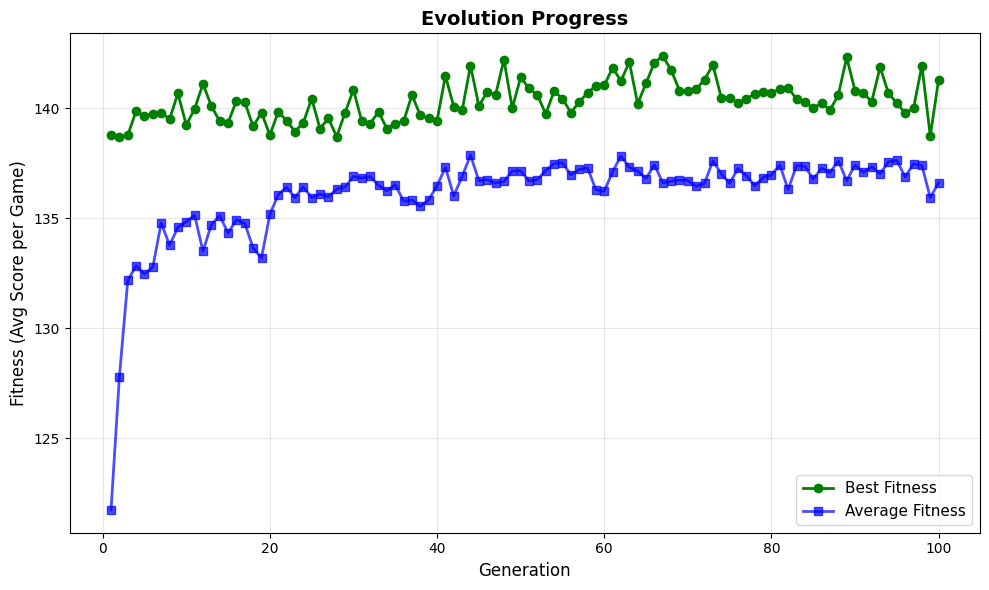


🎉 Your evolved agent's final genes:
   [0.2615500666322691, 0.5374739330894729, 0.01960266534550196, 1.0, 0.0, 0.48791366785579837]


In [ ]:

# ============================================================================
# PART 4: RUN EVOLUTION! 
# ============================================================================

print("\n" + "="*70)
print("🚀 TIME TO EVOLVE YOUR AGENT!")
print("="*70)

my_evolved_agent = evolve(
    generations=100,       # Try: 50, 100, 250
    pop_size=30,         # Try: 15, 20, 30
    opponents=opponent_pool,
    mutation_rate=0.1,  # Try: 0.1, 0.15, 0.2
    elitism=2            # Keep top 2 agents each generation
)

print(f"\n🎉 Your evolved agent's final genes:")
print(f"   {my_evolved_agent.genes}")



In [13]:

# ============================================================================
# PART 5: TEST YOUR AGENT
# ============================================================================

print("\n" + "="*70)
print("⚔️  TESTING YOUR AGENT AGAINST HAND-CODED OPPONENTS")
print("="*70 + "\n")

wins = 0
losses = 0
ties = 0

for opponent in opponent_pool:
    game = Game(my_evolved_agent, opponent, num_rounds=100)
    my_score, opp_score = game.play()
    
    if my_score > opp_score:
        result = "✅ WON"
        wins += 1
    elif my_score < opp_score:
        result = "❌ LOST"
        losses += 1
    else:
        result = "🤝 TIED"
        ties += 1
    
    print(f"vs {opponent.name:25s}: {my_score:3d} - {opp_score:3d}  {result}")

print(f"\n📊 Record: {wins} wins, {losses} losses, {ties} ties")
win_rate = wins / len(opponent_pool) * 100
print(f"🎯 Win Rate: {win_rate:.1f}%")




⚔️  TESTING YOUR AGENT AGAINST HAND-CODED OPPONENTS

vs Always Undercut          :   5 - 480  ❌ LOST
vs Always Invest            : 410 - 135  ✅ WON
vs Prober                   : 265 - 265  🤝 TIED
vs Random (0.9)             : 373 - 158  ✅ WON
vs Hard Majority            : 381 - 176  ✅ WON
vs Suspicious Tit-for-Tat   : 262 - 262  🤝 TIED
vs Adaptive                 : 310 - 210  ✅ WON
vs Random (0.7)             : 229 - 284  ❌ LOST
vs Tit-for-Two-Tats         : 330 - 210  ✅ WON
vs Generous Tit-for-Tat     : 264 - 249  ✅ WON

📊 Record: 6 wins, 2 losses, 2 ties
🎯 Win Rate: 60.0%


# Unit 5 Part 2: Benchmark Analysis

**After running your initial evolution and benchmark tests, answer these questions.**

---

## Performance Summary

Fill in your benchmark results:

| Opponent | Result (W/L/T) | Your Score | Opp Score |
|----------|----------------|------------|-----------|
| Always Invest |WIN|410|135|
| Always Undercut |LOST|5|480|
| Tit-for-Tat |N/A|0|0|
| Grim Trigger |N/A|0|0|
| Pavlov |N/A|0|0|
| Tit-for-Two-Tats |WIN|330|210|
| Generous Tit-for-Tat |WIN|264|249|
| Adaptive |WIN|310|210|
| Random (0.7) |LOST|229|284|
| Random (0.3) |N/A|0|0|
| Prober |TIED|265|265|
| Random (0.9) |WIN|373|158|
| Hard Majority |WIN|381|176|
| Suspicious Tit-for-Tat |TIED|262|262|
| **Total** | 6 W / 2 L / 2 T | | |

---

## Analysis Questions

### 1. What was your agent's worst loss (greatest point differential) and why?
The most significant loss my agent ever had was against Always Undercut, losing by a score of 5-480 and showing a gap of 475 points, which was the highest gap in any result. Gene 0 (0.26) means that my agent still makes some investments in the beginning and Gene 2 (0.02) is low enough for my agent to never retaliate when the opponent keeps defecting. In a match against a player that defects every time, my agent was exploited: every round it invested, It scored 0 while the opponent scored 5. Therefore, the strategy clearly failed to impose any punishment for constant opposition.

---

### 2. What pattern do you see in wins vs. losses?
My agent took on all competitors convincingly because gene 2's almost-zero retaliation and gene 3's forgiveness allowed my agent to continue investing against opponents who hardly retaliated (Always Invest 410-135, Hard Majority 381-176, Random 0.9 373-158, Tit-for-two-Tats 330-210). The two losses occurred against an uncooperative player (Always Undercut) and one with unpredictable behavior (Random 0.7) that sometimes frustrated my agent non-retaliation strategy. The ties occurred against Prober and Suspicious Tit-for-Tat players who take a caution first approach, making it impossible for either team to take a decisive lead.

---

### 3. What would make an agent more competitive?
I would increase gene 2 (the defection response) to see the agent striking back against prolonged attacks instead of just investing in a rival that perpetually undercuts. I would also create conditions for the retaliation to depend on the conduct of the rival rather than a fixed probability. That way, the agent would be able to distinguish between a true enemy such as Always Undercut and simply erratic behaviour of the Random one. It specifically targets one of my greatest losses, losing 475 points due to the lack of adjustment on the part of the agent that was opposed by a player that would not cooperate even once.

---

**Next:** Proceed to Part 3 to implement your improvements!

In [ ]:

# ============================================================================
# PART 6: IMPROVE YOUR AGENT'S ACTION TAKING STRATEGY
# ============================================================================

class ImprovedEvolvableAgent(Agent):
    """
    IMPROVED agent with better gene encoding
    
    Students can modify:
    - Number of genes (currently 6, could add more)
    - What genes control
    - Decision logic (how genes map to actions)
    """
    
    def __init__(self, genes=None, name="Improved Agent"):
        if genes is None:
            genes = [random.random() for _ in range(6)]
        
        self.genes = genes
        super().__init__(name, f"Genes: [{', '.join([f'{g:.2f}' for g in genes])}]")
    
    def choose_action(self) -> bool:
        """
        IMPROVED decision logic - AGGRESSIVE VERSION
        More likely to retaliate, less exploitable
        """
        
        # First 3 rounds: use initial cooperation gene
        if self.round_num < 3:
            return random.random() < self.genes[0]
        
        # Calculate memory window
        memory_length = max(1, int(self.genes[4] * 10) + 1)
        recent_history = self.history[-memory_length:]
        cooperation_rate = sum(recent_history) / len(recent_history)

        retaliation_threshold = self.genes[5]

        if cooperation_rate >= retaliation_threshold:
            coop_prob = self.genes[1] * min(1.0, cooperation_rate + 0.2)
            return random.random() < coop_prob
        else:
            if random.random() < self.genes[2]:
                return UNDERCUT
            else:
                return random.random() < self.genes[3]
    
    def save_to_file(self, filename):
        """Save agent to JSON"""
        data = {
            'name': self.name,
            'genes': self.genes,
            'description': self.description
        }
        with open(filename, 'w') as f:
            json.dump(data, f, indent=2)
        print(f"✅ Agent saved to {filename}")


🔧 EVOLVING YOUR IMPROVED AGENT!

🧬 EVOLUTION STARTING (Improved Agent)
Population: 30 | Generations: 100 | Mutation: 0.1
Opponents: 10 | Elitism: 2

Gen   1/100: Best=110.47 | Avg= 99.90 | Genes=['0.99', '0.74', '0.47', '0.42', '0.92', '0.33']
Gen   2/100: Best=115.80 | Avg=106.95 | Genes=['0.74', '0.94', '0.64', '0.65', '0.40', '0.21']
Gen   3/100: Best=121.50 | Avg=107.99 | Genes=['0.74', '1.00', '0.25', '0.43', '0.86', '0.46']
Gen   4/100: Best=121.50 | Avg=110.02 | Genes=['0.74', '1.00', '0.25', '0.43', '0.40', '0.21']
Gen   5/100: Best=121.50 | Avg=109.94 | Genes=['0.74', '0.94', '0.32', '0.14', '0.86', '0.01']
Gen   6/100: Best=121.50 | Avg=111.48 | Genes=['0.74', '1.00', '0.25', '0.14', '0.86', '0.01']
Gen   7/100: Best=125.67 | Avg=114.58 | Genes=['0.74', '1.00', '0.32', '0.09', '0.77', '0.01']
Gen   8/100: Best=126.93 | Avg=113.69 | Genes=['0.74', '1.00', '0.32', '0.14', '0.34', '0.29']
Gen   9/100: Best=126.93 | Avg=112.77 | Genes=['0.84', '1.00', '0.32', '0.24', '0.77', '0.

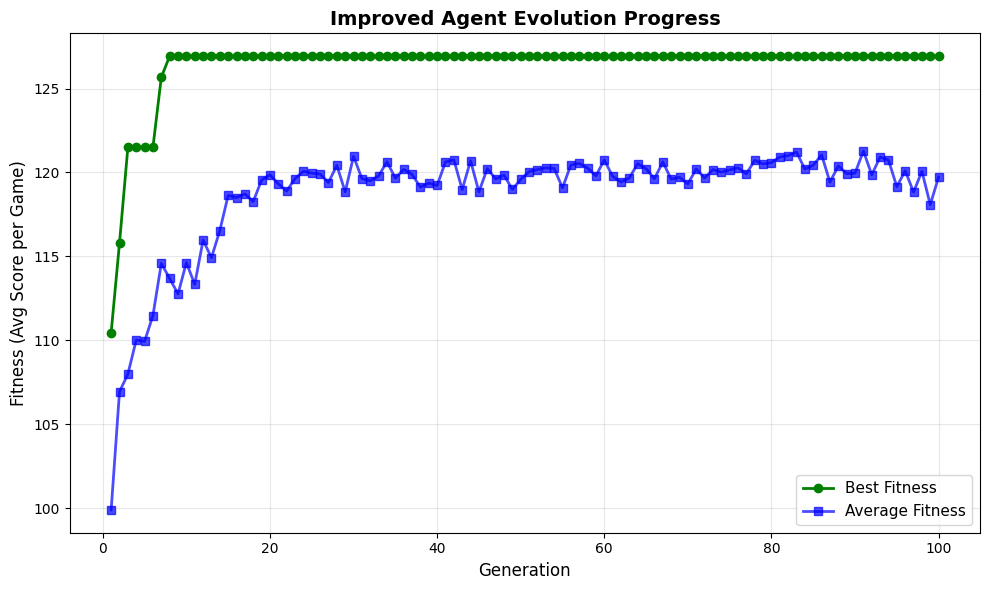


🎉 Your improved agent's final genes:
   [0.7378386062536859, 1.0, 0.3198439876294813, 0.14408434764107342, 0.3410999818473446, 0.290503294583385]


In [ ]:
# ============================================================================
# PART 7: EVOLVE YOUR IMPROVED AGENT
# ============================================================================


print("\n" + "="*70)
print("🔧 EVOLVING YOUR IMPROVED AGENT!")
print("="*70)


def evolve_improved(generations=25, pop_size=20, opponents=None, mutation_rate=0.15, elitism=2):
    """
    Evolve using the ImprovedEvolvableAgent class
    (Same as evolve() but uses ImprovedEvolvableAgent instead of EvolvableAgent)
    """
    if opponents is None:
        opponents = opponent_pool
    
    print(f"\n🧬 EVOLUTION STARTING (Improved Agent)")
    print(f"{'='*70}")
    print(f"Population: {pop_size} | Generations: {generations} | Mutation: {mutation_rate}")
    print(f"Opponents: {len(opponents)} | Elitism: {elitism}")
    print(f"{'='*70}\n")
    
    best_fitness_history = []
    avg_fitness_history = []
    
    # Initialize population with ImprovedEvolvableAgent
    population = [ImprovedEvolvableAgent(name=f"Agent_{i}") for i in range(pop_size)]
    
    best_overall_agent = None
    best_overall_fitness = -float('inf')
    
    for gen in range(generations):
        # Evaluate fitness
        fitnesses = []
        for agent in population:
            fitness = evaluate_fitness(agent, opponents, num_rounds=50)
            fitnesses.append(fitness)
        
        # Track best
        best_fitness = max(fitnesses)
        avg_fitness = sum(fitnesses) / len(fitnesses)
        
        # Update best overall
        best_idx = fitnesses.index(best_fitness)
        if best_fitness > best_overall_fitness:
            best_overall_fitness = best_fitness
            best_overall_agent = ImprovedEvolvableAgent(genes=population[best_idx].genes.copy())
        
        best_fitness_history.append(best_overall_fitness)
        avg_fitness_history.append(avg_fitness)
        
        print(f"Gen {gen+1:3d}/{generations}: "
              f"Best={best_overall_fitness:6.2f} | Avg={avg_fitness:6.2f} | "
              f"Genes={[f'{g:.2f}' for g in population[best_idx].genes]}")
        
        # Create next generation
        if gen < generations - 1:
            sorted_indices = sorted(range(len(fitnesses)), 
                                  key=lambda i: fitnesses[i], 
                                  reverse=True)
            
            # Elitism
            next_population = []
            for i in range(elitism):
                elite_genes = population[sorted_indices[i]].genes.copy()
                next_population.append(ImprovedEvolvableAgent(genes=elite_genes))
            
            # Selection
            selected = tournament_selection(population, fitnesses)
            
            # Crossover and mutation
            while len(next_population) < pop_size:
                parent1, parent2 = random.sample(selected, 2)
                child = crossover_and_mutate(parent1, parent2, mutation_rate)
                # Convert to ImprovedEvolvableAgent
                next_population.append(ImprovedEvolvableAgent(genes=child.genes))
            
            population = next_population
    
    print(f"\n{'='*70}")
    print(f"✅ EVOLUTION COMPLETE!")
    print(f"🏆 Best fitness achieved: {best_overall_fitness:.2f}")
    print(f"{'='*70}\n")
    
    # Plot
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, generations+1), best_fitness_history, 
             label='Best Fitness', linewidth=2, color='green', marker='o')
    plt.plot(range(1, generations+1), avg_fitness_history, 
             label='Average Fitness', linewidth=2, color='blue', marker='s', alpha=0.7)
    plt.xlabel('Generation', fontsize=12)
    plt.ylabel('Fitness (Avg Score per Game)', fontsize=12)
    plt.title('Improved Agent Evolution Progress', fontsize=14, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    return best_overall_agent

my_improved_agent = evolve_improved(
    generations=100,      # Try: 20, 30, 50
    pop_size=30,         # Try: 15, 20, 30
    opponents=opponent_pool,
    mutation_rate=0.1,   # Try: 0.1, 0.15, 0.2
    elitism=2            # Keep top 2 agents each generation
)

print(f"\n🎉 Your improved agent's final genes:")
print(f"   {my_improved_agent.genes}")

In [12]:

# ============================================================================
# PART 8.1: Compare: Original vs Improved
# ============================================================================

print("\n" + "="*70)
print("📊 COMPARISON: Original vs Improved Agent")
print("="*70 + "\n")

print("ORIGINAL AGENT:")
wins_orig = 0
for opponent in opponent_pool:
    game = Game(my_evolved_agent, opponent, num_rounds=100)
    my_score, opp_score = game.play()
    if my_score > opp_score:
        wins_orig += 1
        result = "✅ WON"
    elif my_score < opp_score:
        result = "❌ LOST"
    else:
        result = "🤝 TIED"
    print(f"vs {opponent.name:25s}: {my_score:3d} - {opp_score:3d}  {result}")

print(f"\nOriginal Win Rate: {wins_orig / len(opponent_pool) * 100:.1f}%")

print("\n" + "-"*70 + "\n")

print("IMPROVED AGENT:")
wins_improved = 0
for opponent in opponent_pool:
    game = Game(my_improved_agent, opponent, num_rounds=100)
    my_score, opp_score = game.play()
    if my_score > opp_score:
        wins_improved += 1
        result = "✅ WON"
    elif my_score < opp_score:
        result = "❌ LOST"
    else:
        result = "🤝 TIED"
    print(f"vs {opponent.name:25s}: {my_score:3d} - {opp_score:3d}  {result}")

print(f"\nImproved Win Rate: {wins_improved / len(opponent_pool) * 100:.1f}%")

print("\n" + "="*70)
print(f"📈 IMPROVEMENT: +{wins_improved - wins_orig} wins")
print("="*70)


# ============================================================================
# GENERALIZATION TEST: Full Opponent Pool
# ============================================================================

print("\n" + "="*70)
print("🌍 GENERALIZATION TEST: Against ALL Possible Opponents")
print("="*70 + "\n")

print("Testing improved agent against the FULL opponent library:")
print("(including agents it was NOT trained on)\n")

wins_full = 0
losses_full = 0
ties_full = 0

for opponent in full_opponent_pool:
    game = Game(my_improved_agent, opponent, num_rounds=100)
    my_score, opp_score = game.play()
    
    if my_score > opp_score:
        result = "✅ WON"
        wins_full += 1
    elif my_score < opp_score:
        result = "❌ LOST"
        losses_full += 1
    else:
        result = "🤝 TIED"
        ties_full += 1
    
    # Mark if this was a training opponent
    trained_on = "📚" if any(opponent.name == o.name for o in opponent_pool) else "🆕"
    print(f"{trained_on} vs {opponent.name:25s}: {my_score:3d} - {opp_score:3d}  {result}")

print(f"\n📊 Results against ALL {len(full_opponent_pool)} opponents:")
print(f"   Wins: {wins_full} | Losses: {losses_full} | Ties: {ties_full}")
print(f"   Win Rate: {wins_full / len(full_opponent_pool) * 100:.1f}%")
print(f"\n💡 Legend: 📚 = Trained on this opponent | 🆕 = Never seen before")
print("="*70)


📊 COMPARISON: Original vs Improved Agent

ORIGINAL AGENT:
vs Adaptive                 : 284 - 254  ✅ WON
vs Prober                   : 248 - 243  ✅ WON
vs Random (0.1)             :  47 - 442  ❌ LOST
vs Tit-for-Two-Tats         : 336 - 216  ✅ WON
vs Suspicious Tit-for-Tat   : 251 - 256  ❌ LOST
vs Grim Trigger             :   9 - 479  ❌ LOST
vs Always Invest            : 376 - 186  ✅ WON
vs Pavlov                   :  59 - 429  ❌ LOST
vs Always Undercut          :   3 - 488  ❌ LOST
vs Hard Majority            : 340 - 190  ✅ WON

Original Win Rate: 50.0%

----------------------------------------------------------------------

IMPROVED AGENT:
vs Adaptive                 : 304 - 294  ✅ WON
vs Prober                   : 299 - 299  🤝 TIED
vs Random (0.1)             : 112 - 157  ❌ LOST
vs Tit-for-Two-Tats         : 302 - 297  ✅ WON
vs Suspicious Tit-for-Tat   : 297 - 302  ❌ LOST
vs Grim Trigger             : 300 - 300  🤝 TIED
vs Always Invest            : 302 - 297  ✅ WON
vs Pavlov         

In [13]:

# ============================================================================
# PART 8.2: Compete in your final tournament
# ============================================================================

print("\n" + "="*70)
print("🏆 FULL TOURNAMENT COMPARISON")
print("="*70 + "\n")

# Create tournament with original agent
print("Running tournament with ORIGINAL agent...")
original_tournament_agents = full_opponent_pool + [my_evolved_agent]
original_tournament = Tournament(original_tournament_agents, rounds_per_match=100, num_tournaments=1)
original_tournament.run_tournament()

# Create tournament with improved agent
print("\n" + "-"*70)
print("\nRunning tournament with IMPROVED agent...")
improved_tournament_agents = full_opponent_pool + [my_improved_agent]
improved_tournament = Tournament(improved_tournament_agents, rounds_per_match=100, num_tournaments=1)
improved_tournament.run_tournament()

# Compare rankings
print("\n" + "="*70)
print("📊 TOURNAMENT RESULTS COMPARISON")
print("="*70 + "\n")

original_rankings = original_tournament.get_rankings()
improved_rankings = improved_tournament.get_rankings()

# Find where each agent placed
original_rank = None
improved_rank = None
original_score = None
improved_score = None

for rank, (name, score) in enumerate(original_rankings, 1):
    if name == my_evolved_agent.name:
        original_rank = rank
        original_score = score

for rank, (name, score) in enumerate(improved_rankings, 1):
    if name == my_improved_agent.name:
        improved_rank = rank
        improved_score = score

print(f"ORIGINAL AGENT:")
print(f"  Rank: {original_rank} / {len(original_rankings)}")
print(f"  Total Score: {original_score:,}")
print()
print(f"IMPROVED AGENT:")
print(f"  Rank: {improved_rank} / {len(improved_rankings)}")
print(f"  Total Score: {improved_score:,}")
print()
print(f"IMPROVEMENT:")
print(f"  Rank Change: {original_rank - improved_rank} positions {'⬆️' if improved_rank < original_rank else '⬇️' if improved_rank > original_rank else '➡️'}")
print(f"  Score Change: +{improved_score - original_score:,} points ({(improved_score - original_score)/original_score*100:.1f}%)")
print("="*70)

# Show full leaderboard
print("\n🏆 IMPROVED AGENT TOURNAMENT LEADERBOARD:")
print("=" * 50)
for rank, (name, score) in enumerate(improved_rankings, 1):
    emoji = "🥇" if rank == 1 else "🥈" if rank == 2 else "🥉" if rank == 3 else "  "
    marker = " ⭐ YOUR AGENT" if name == my_improved_agent.name else ""
    print(f"{emoji} {rank:2d}. {name:25s}: {score:,} points{marker}")


🏆 FULL TOURNAMENT COMPARISON

Running tournament with ORIGINAL agent...
Running 1 tournament(s) with 19 agents...
Match 1/342: Always Invest vs Tit-for-Tat
Match 2/342: Always Invest vs Grim Trigger
Match 3/342: Always Invest vs Pavlov
Match 4/342: Always Invest vs Tit-for-Two-Tats
Match 5/342: Always Invest vs Generous Tit-for-Tat
Match 6/342: Always Invest vs Adaptive
Match 7/342: Always Invest vs Always Undercut
Match 8/342: Always Invest vs Suspicious Tit-for-Tat
Match 9/342: Always Invest vs Gradual
Match 10/342: Always Invest vs Prober
Match 11/342: Always Invest vs Hard Majority
Match 12/342: Always Invest vs Soft Majority
Match 13/342: Always Invest vs Random (0.9)
Match 14/342: Always Invest vs Random (0.7)
Match 15/342: Always Invest vs Random (0.5)
Match 16/342: Always Invest vs Random (0.3)
Match 17/342: Always Invest vs Random (0.1)
Match 18/342: Always Invest vs Evolved Agent
Match 19/342: Tit-for-Tat vs Always Invest
Match 20/342: Tit-for-Tat vs Grim Trigger
Match 21/34

In [ ]:
# ============================================================================
# PART 9: Export Complete Agent as Python Module
# ============================================================================

import inspect
from datetime import datetime

def export_complete_agent(agent, student_name, generations=100, final_fitness=None):
    """
    Export agent as a complete, standalone Python module.
    This preserves BOTH genes AND decision logic so your strategy maintains
    its competitive edge in the tournament!
    
    Args:
        agent: Your evolved ImprovedEvolvableAgent
        student_name: Your name (will be used in class name, e.g., "JohnSmith")
        generations: Number of generations you evolved for
        final_fitness: Your agent's final fitness score (optional)
    
    Returns:
        filename of the exported Python file
    """
    
    # Clean up student name for valid Python class name (remove spaces, special chars)
    clean_name = ''.join(c for c in student_name if c.isalnum())
    
    # Get the actual decision logic code
    decision_code = inspect.getsource(agent.choose_action)
    
    # The source code already has proper indentation from the class,
    # so we don't need to add extra indentation
    
    # Get training opponent names if available
    try:
        opponent_names = [opp.name for opp in opponent_pool]
        opponent_info = f"Trained against: {', '.join(opponent_names[:5])}{'...' if len(opponent_names) > 5 else ''}"
    except:
        opponent_info = "Training opponents: [info not available]"
    
    # Build the complete Python module
    code = f'''#!/usr/bin/env python
"""
Tournament Agent: {agent.name}
Student: {student_name}
Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}

Evolution Details:
- Generations: {generations}
- Final Fitness: {final_fitness if final_fitness else 'N/A'}
- {opponent_info}

Strategy: {agent.description}
"""

from agents import Agent, INVEST, UNDERCUT
import random


class {clean_name}Agent(Agent):
    """
    {agent.name}
    
    {agent.description}
    
    Evolved Genes: {agent.genes}
    """
    
    def __init__(self):
        # These genes were evolved through {generations} generations
        self.genes = {agent.genes}
        
        # Required for tournament compatibility
        self.student_name = "{student_name}"
        
        super().__init__(
            name="{agent.name}",
            description="{agent.description}"
        )
    
{decision_code}


# Convenience function for tournament loading
def get_agent():
    """Return an instance of this agent for tournament use"""
    return {clean_name}Agent()


if __name__ == "__main__":
    # Test that the agent can be instantiated
    agent = get_agent()
    print(f"✅ Agent loaded successfully: {{agent.name}}")
    print(f"   Genes: {{agent.genes}}")
    print(f"   Description: {{agent.description}}")
'''
    
    # Save to file
    filename = f"{clean_name.lower()}_tournament_agent.py"
    with open(filename, 'w', encoding='utf-8') as f:
        f.write(code)
    
    print("="*70)
    print("✅ COMPLETE TOURNAMENT AGENT EXPORTED!")
    print("="*70)
    print(f"📄 File: {filename}")
    print(f"🏷️  Class: {clean_name}Agent")
    print(f"🧬 Genes: {agent.genes}")
    print()
    print("📦 What's included:")
    print("   ✓ Your evolved gene values")
    print("   ✓ Your complete decision logic (choose_action method)")
    print("   ✓ All metadata and documentation")
    print()
    print("🎯 Next Steps:")
    print(f"   1. Download '{filename}' from Jupyter")
    print("   2. Submit this .py file for the Unit 6 tournament")
    print("   3. Your strategy will compete exactly as it evolved!")
    print()
    print("🧪 Test your export:")
    print(f"   from {filename[:-3]} import get_agent")
    print("   my_agent = get_agent()")
    print("="*70)
    
    return filename


# ============================================================================
# RUN THIS: Export your improved agent
# ============================================================================

print("\n" + "="*70)
print("💾 EXPORTING YOUR TOURNAMENT AGENT")
print("="*70 + "\n")

STUDENT_NAME = "Andrew Ocasio Serrano" 

my_improved_agent.name = "Cleanthes"  # <-- CHANGE THIS! (e.g., "Vengeful Cooperator", "Strategic Punisher")
my_improved_agent.description = "Starts cooperative and rewards cooperation fully, but has a low tolerance for defection. Retaliates once an opponent crosses a low hostility threshold and rarely forgives, avoiding exploitation by consistently hostile opponents."  # <-- CHANGE THIS! (e.g., "Cooperates with cooperative opponents but retaliates quickly against defectors")

print(f"Agent Name: {my_improved_agent.name}")
print(f"Description: {my_improved_agent.description}")
print(f"Genes: {[f'{g:.2f}' for g in my_improved_agent.genes]}\n")

# Export with all the context
exported_file = export_complete_agent(
    agent=my_improved_agent,
    student_name=STUDENT_NAME,
    generations=100,  # Update if you used different value
    final_fitness=None  # Optionally add your best fitness score (e.g., 85.2)
)

print(f"\n✨ Your agent is ready for tournament competition!")
print(f"   Unlike JSON exports, this preserves your evolved strategy.\n")



💾 EXPORTING YOUR TOURNAMENT AGENT

Agent Name: Cleanthes
Description: Starts cooperative and rewards cooperation fully, but has a low tolerance for defection. Retaliates once an opponent crosses a low hostility threshold and rarely forgives, avoiding exploitation by consistently hostile opponents.
Genes: ['0.74', '1.00', '0.32', '0.14', '0.34', '0.29']

✅ COMPLETE TOURNAMENT AGENT EXPORTED!
📄 File: andrewocasioserrano_tournament_agent.py
🏷️  Class: AndrewOcasioSerranoAgent
🧬 Genes: [0.7378386062536859, 1.0, 0.3198439876294813, 0.14408434764107342, 0.3410999818473446, 0.290503294583385]

📦 What's included:
   ✓ Your evolved gene values
   ✓ Your complete decision logic (choose_action method)
   ✓ All metadata and documentation

🎯 Next Steps:
   1. Download 'andrewocasioserrano_tournament_agent.py' from Jupyter
   2. Submit this .py file for the Unit 6 tournament
   3. Your strategy will compete exactly as it evolved!

🧪 Test your export:
   from andrewocasioserrano_tournament_agent imp

## Post-Evolution Reflection Questions

### 1. Generalization Analysis
The agent that I utilized either tied every previously unseen strategy or lost to a trained strategy it had already faced (Grim Trigger), during the testing of its generalization abilities. All the games the competitors, such as Tit-for-Tat, Generous Tit-for-Tat, Soft Majority, and others, played against my agent ended in ties, even though the agent had no prior training in these strategies. On the other hand, the same agent lost against every variation of the Random strategy, regardless of whether it had trained on that variation or not. Such results indicate that the agent didn't overfit to the strategies used for training, as it was able to generalize its knowledge from the training process. However, the agent shows a failure in random situations where it doesn't have any patterns to rely on when dealing with the cooperation rates of the opponents. Therefore, since the agent has evolved in the context of structured movements, it has acquired the ability to use that strategy, but loses against the noisy strategies.

### 2. Tournament Performance
My final rank at the tournament was sixth out of 19 agents, reflecting a total score of 4,653 points and an improvement of 741 points (18.9%) from my original position of 16th. Above me were Gradual, Grim Trigger, Generous Tit-for-Tat, Tit-for-Tat and Hard Majority strategies, those who rely either on firm retaliation or patience. Below me, on the other hand, there were agents with no adaptive strategy, like all of the Random variations, Always Invest, and Always Undercut.

### 3. Strategy Analysis
My characteristics of evolution: [0.74, 1.00, 0.32, 0.14, 0.34, 0.29]. To clarify, my agent has a cooperative nature to start with (gene 0 = 0.74) and will reciprocate cooperation (gene 1 = 1.00). The tolerance for aggressive moves is low (gene 5 = 0.29), retaliation is only moderate, not severe, once triggered (gene 2 = 0.32). The agent does not forgive often (gene 3 = 0.14). Evolution has probably learned how to balance the levels of tolerance to prevent being taken advantage of in the early stages without wasting points on opponents that had already shown readiness to act aggressively.

### 4. Trade-offs
My agent defeats cooperating players or those who consistently respond to actions of their rivals in the same way (Always Invest, Hard Majority, Tit-for-Two-Tats). However, it loses badly against players who do not follow a determined strategy and all types of Random players, even though it suffers a much smaller loss against Always Undercut than my first agent. If I were to redesign it for Unit 6, I would add a gene that detects whether opponents behavior is random rather than deliberate and enables my agent to use a strategy of pure defection against noise instead of playing senselessly in search of an exploitable pattern.

### 5. The Environment Matters
I was developed by competing against a random selection of 10 opponents, and I tested against all 19 total opponents. Moreover, Unit 6 will contain more than 30 agents developed by students that I've never seen before. Because my agent performed exceptionally well against strategies that it was not trained for, I have high expectations for its performance against the new opponents. However, if many of my classmates create agents that are random or exploit other strategies in a non-systematic way, the weaknesses in my agent will once again be exposed.